### Understand the business scenario and problem

The HR department at Salifort Motors wants to take some initiatives to improve employee satisfaction levels at the company. They collected data from employees, but now they don’t know what to do with it. They refer to you as a data analytics professional and ask you to provide data-driven suggestions based on your understanding of the data. They have the following question: what’s likely to make the employee leave the company?

Your goals in this project are to analyze the data collected by the HR department and to build a model that predicts whether or not an employee will leave the company. 

If you can predict employees likely to quit, it might be possible to identify factors that contribute to their leaving. Because it is time-consuming and expensive to find, interview, and hire new employees, increasing employee retention will be beneficial to the company.

In this [dataset](https://www.kaggle.com/datasets/mfaisalqureshi/hr-analytics-and-job-prediction?select=HR_comma_sep.csv), there are 14,999 rows, 10 columns, and these variables: 

Variable  |Description |
-----|-----| 
satisfaction_level|Employee-reported job satisfaction level [0&ndash;1]|
last_evaluation|Score of employee's last performance review [0&ndash;1]|
number_project|Number of projects employee contributes to|
average_monthly_hours|Average number of hours employee worked per month|
time_spend_company|How long the employee has been with the company (years)
Work_accident|Whether or not the employee experienced an accident while at work
left|Whether or not the employee left the company
promotion_last_5years|Whether or not the employee was promoted in the last 5 years
Department|The employee's department
salary|The employee's salary (U.S. dollars)

# Exploratory Data Analysis

In [159]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import plotly.express as px


In [ ]:
sns.set_theme(style="darkgrid")

In [37]:
df = pd.read_csv("data/raw/HR_capstone_dataset.csv")

In [38]:
df.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


In [39]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     14999 non-null  float64
 1   last_evaluation        14999 non-null  float64
 2   number_project         14999 non-null  int64  
 3   average_montly_hours   14999 non-null  int64  
 4   time_spend_company     14999 non-null  int64  
 5   Work_accident          14999 non-null  int64  
 6   left                   14999 non-null  int64  
 7   promotion_last_5years  14999 non-null  int64  
 8   Department             14999 non-null  object 
 9   salary                 14999 non-null  object 
dtypes: float64(2), int64(6), object(2)
memory usage: 1.1+ MB


My findings:

10 features, 14,999 rows

No null values: this is good,

Proper data types for all features



In [40]:
df.describe()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years
count,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000
mean,0.612834,0.716102,3.803054,201.050337,3.498233,0.144610,0.238083,0.021268
std,0.248631,0.171169,1.232592,49.943099,1.460136,0.351719,0.425924,0.144281
min,0.090000,0.360000,2.000000,96.000000,2.000000,0.000000,0.000000,0.000000
25%,0.440000,0.560000,3.000000,156.000000,3.000000,0.000000,0.000000,0.000000
50%,0.640000,0.720000,4.000000,200.000000,3.000000,0.000000,0.000000,0.000000
75%,0.820000,0.870000,5.000000,245.000000,4.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,7.000000,310.000000,10.000000,1.000000,1.000000,1.000000


My findings:

Average Satisfaction is meh around 61, median 64

Last evaluation suggests employee performance reviews are good. 

Employees do average of 4 projects, and min of 2

Employees work an average of 200 hrs per month, std of 50ish

Average time spent in company 3.5 yrs, most people in range of (2,5) min of 2 yrs. max of 10

Work accidents are very rare, only one in 10 experiencing an accident.

Promotions are very rare, it is more common to have an accident than get a promotion here lol.




In [41]:
df.duplicated().sum()

np.int64(3008)

In [ ]:
# show duplicated rows where left = 0
df[df.duplicated()]["left"].value_counts()

left
1    1580
0    1428
Name: count, dtype: int64

In [43]:
df.left.value_counts()

left
0    11428
1     3571
Name: count, dtype: int64

In [44]:
df = df.drop_duplicates()

In [45]:
df.left.value_counts()

left
0    10000
1     1991
Name: count, dtype: int64

In [143]:
df.to_csv("data/processed/HR_capstone_dataset.csv", index=False)

---

# Univariate Analysis

In [ ]:
df.columns.to_list()

['satisfaction_level',
 'last_evaluation',
 'number_project',
 'average_montly_hours',
 'time_spend_company',
 'Work_accident',
 'left',
 'promotion_last_5years',
 'Department',
 'salary']

In [ ]:
def inspect(feature_name):
    print(df[feature_name].describe())
    sns.boxplot(data=df, x=feature_name)
    plt.show()
    sns.histplot(data=df, x=feature_name, hue="left")
    plt.show()

count    11991.000000
mean         0.629658
std          0.241070
min          0.090000
25%          0.480000
50%          0.660000
75%          0.820000
max          1.000000
Name: satisfaction_level, dtype: float64


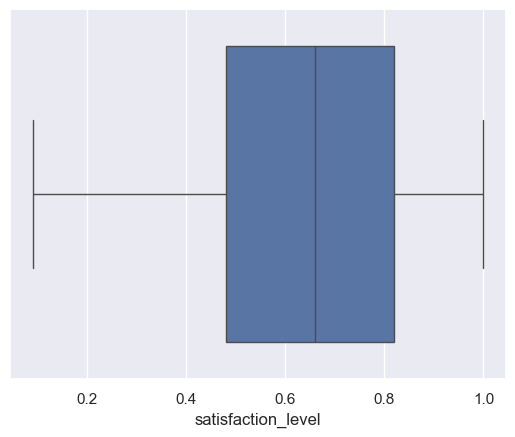

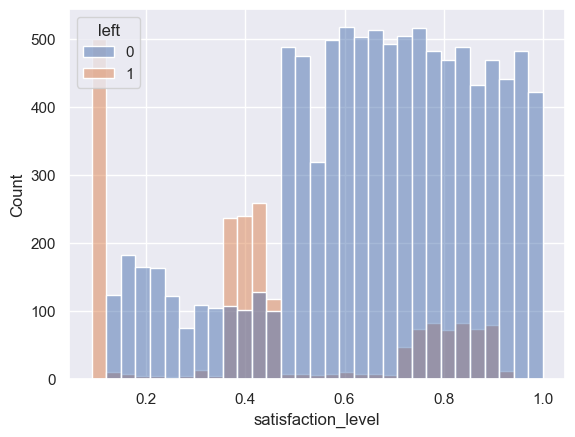

In [ ]:
inspect("satisfaction_level")

Bins

0 - 0.1 Very Low

0.1 - 0.35 Low

0.35 - 0.45 Okay

0.45 - 0.7 average

0.7 - 0.9 Good

>0.9 Very Good


In [ ]:
px.histogram(df, x="satisfaction_level", color="left")

People with very low satisfaction are very likely to leave, distribution is left skewed.

Most people have a somewhat or higher satisfaction

There's a spike in exits at around 0.4 satisfaction level which should be investigated further

count    11991.000000
mean         0.716683
std          0.168343
min          0.360000
25%          0.570000
50%          0.720000
75%          0.860000
max          1.000000
Name: last_evaluation, dtype: float64


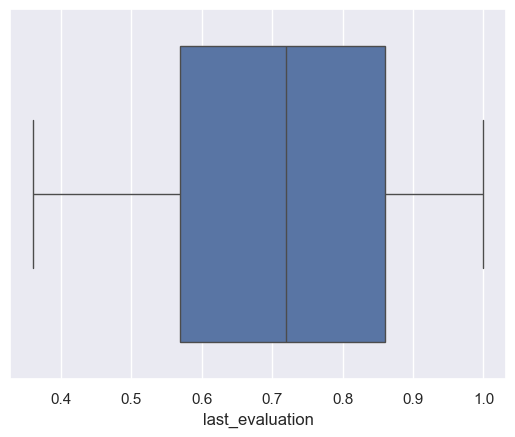

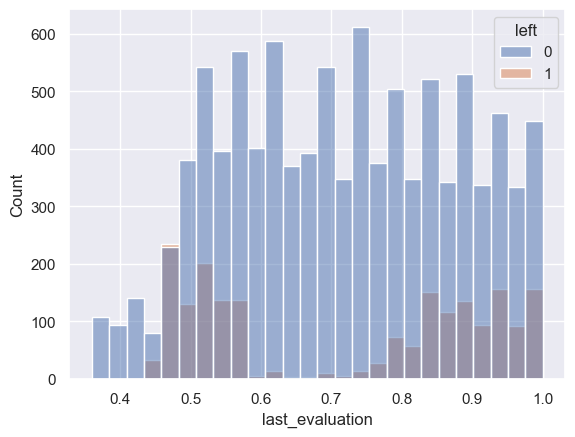

In [ ]:
inspect("last_evaluation")

Bins:

0 - 0.45 Low

0.45 - 0.60 Average

0.60 - 0.75 Good

0.75 - 0.95 Very Good

0.95 - 1.00 Excellent


In [ ]:
px.histogram(df, x="last_evaluation", color="left")

Everyone score over 36 at least

50% score over 76, while most have scores above 0.5

Exits are spiking around 0.45 to 0.6 then they drop and start to rise steadily around 0.8

People who score around 50 and those who score very high tend to leave

count    11991.000000
mean         3.802852
std          1.163238
min          2.000000
25%          3.000000
50%          4.000000
75%          5.000000
max          7.000000
Name: number_project, dtype: float64


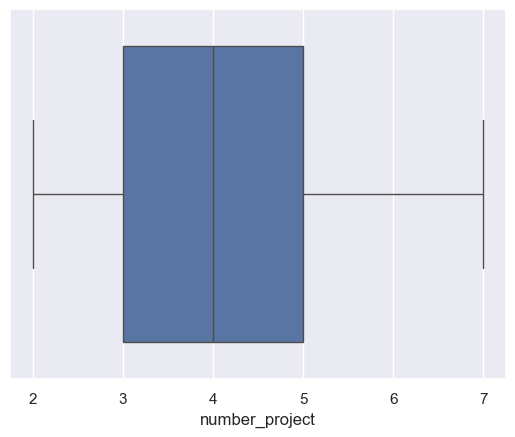

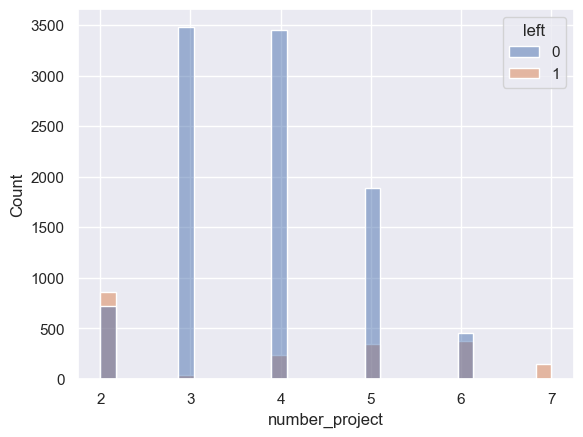

In [ ]:
inspect("number_project")

Bins

2 - Low

3 - 5 Medium

6 - 7 High

In [ ]:
df.groupby("number_project")["left"].value_counts(normalize=True)

number_project  left
2               1       0.541719
                0       0.458281
3               0       0.989205
                1       0.010795
4               0       0.935685
                1       0.064315
5               0       0.846395
                1       0.153605
6               0       0.550847
                1       0.449153
7               1       1.000000
Name: proportion, dtype: float64

Most of the employees do 3 or 4 project

Most of the exiters did only two projects

All employees who did 7 projects exited!


count    11991.000000
mean       200.473522
std         48.727813
min         96.000000
25%        157.000000
50%        200.000000
75%        243.000000
max        310.000000
Name: average_montly_hours, dtype: float64


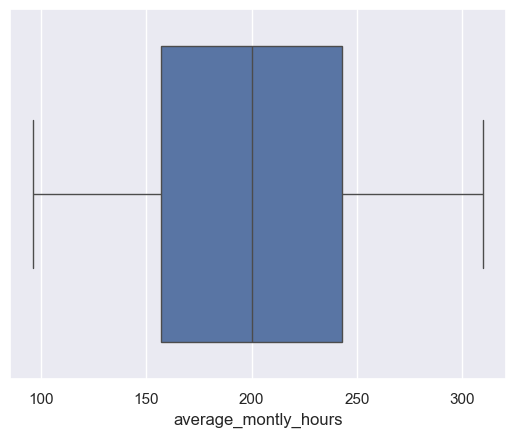

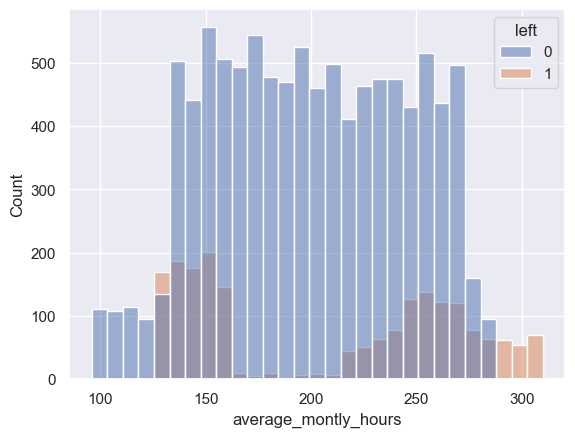

In [ ]:
inspect("average_montly_hours")

Bins:
0 - 125

125 - 165

165 - 225

225 - 290

> 290 deffo leaving


In [ ]:
import plotly.express as px

px.histogram(df, x="average_montly_hours", color="left")

In [ ]:
df[df["average_montly_hours"] > 275]["left"].value_counts(normalize=True)

left
1    0.648107
0    0.351893
Name: proportion, dtype: float64

Overworked employees (>275) tend to exit the company 

Interestingly employees working around 125 to 155 hrs are also likely to exit

In [85]:
df.time_spend_company.describe()

count    11991.000000
mean         3.364857
std          1.330240
min          2.000000
25%          3.000000
50%          3.000000
75%          4.000000
max         10.000000
Name: time_spend_company, dtype: float64

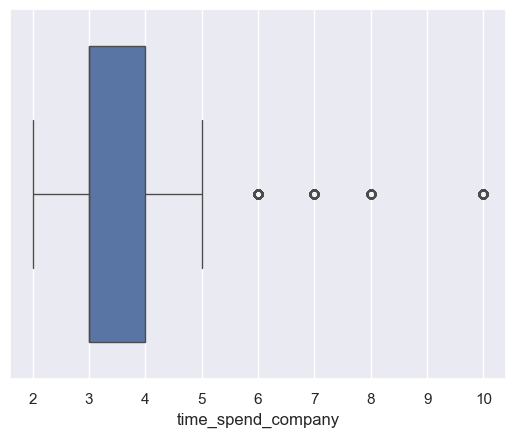

In [ ]:
sns.boxplot(data=df, x="time_spend_company");


In [ ]:
df[df.time_spend_company >= 6]["time_spend_company"].value_counts().sort_index()

time_spend_company
6     542
7      94
8      81
10    107
Name: count, dtype: int64

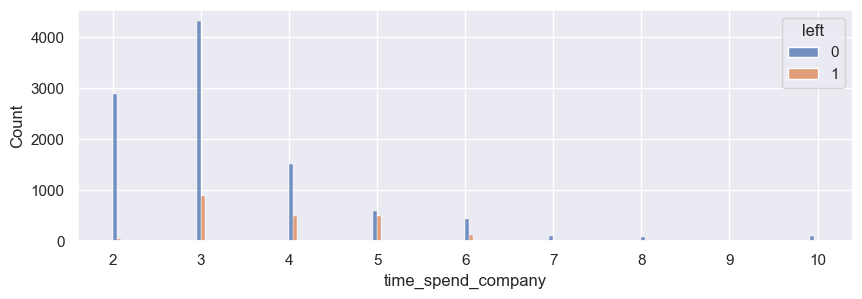

In [ ]:
plt.figure(figsize=(10, 3))
sns.histplot(data=df, x="time_spend_company", hue="left", multiple="dodge");

Bins:

2 Low

3 - 4 Med

4 - 5 Long

6 + Very Long


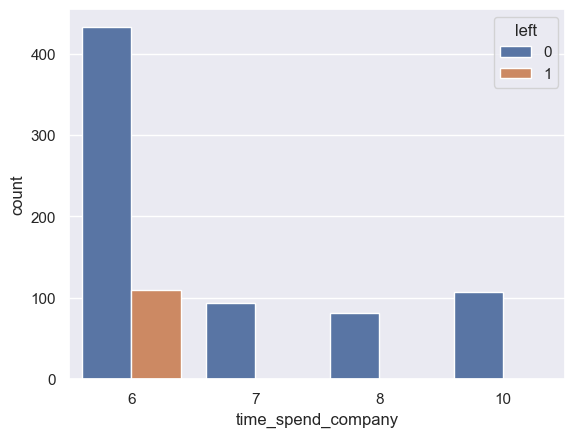

In [ ]:
sns.countplot(data=df[df.time_spend_company >= 6], x="time_spend_company", hue="left");

Time spent in company is right skewed, most people spend 3 to 4 years,

Most exits come from employees working 3 to 5 years

None of the employees working 7+ years leave the company


In [163]:
df.Work_accident.value_counts()

Work_accident
0    10141
1     1850
Name: count, dtype: int64

In [164]:
df.groupby("Work_accident")["left"].value_counts(normalize=True)

Work_accident  left
0              0       0.814022
               1       0.185978
1              0       0.943243
               1       0.056757
Name: proportion, dtype: float64

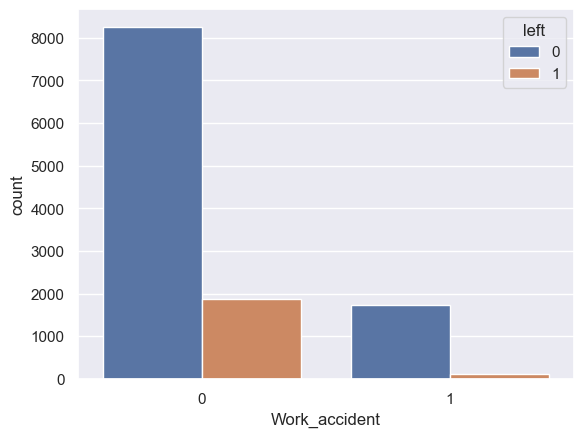

In [165]:
sns.countplot(data=df, x="Work_accident", hue="left");

Work accidents do not affect employee exits



In [ ]:
df["promotion_last_5years"].value_counts(normalize=True)

promotion_last_5years
0    0.983071
1    0.016929
Name: proportion, dtype: float64

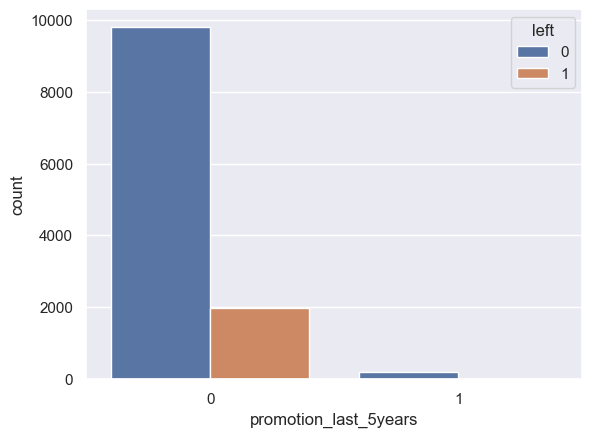

In [ ]:
sns.countplot(data=df, x="promotion_last_5years", hue="left");

In [ ]:
print(
    "People who exited even after being promoted in the last 5 years: ",
    len(df[(df["promotion_last_5years"] == 1) & df["left"] == 1]),
)

People who exited even after being promoted in the last 5 years:  8


Chances of a promotion here are less than 1%

Those who do get promoted don't tend to leave

8 people left even when they got a promotion, out of 208 (3%)

In [ ]:
df["Department"].describe()

count     11991
unique       10
top       sales
freq       3239
Name: Department, dtype: object

In [ ]:
df["Department"].unique()

array(['sales', 'accounting', 'hr', 'technical', 'support', 'management',
       'IT', 'product_mng', 'marketing', 'RandD'], dtype=object)

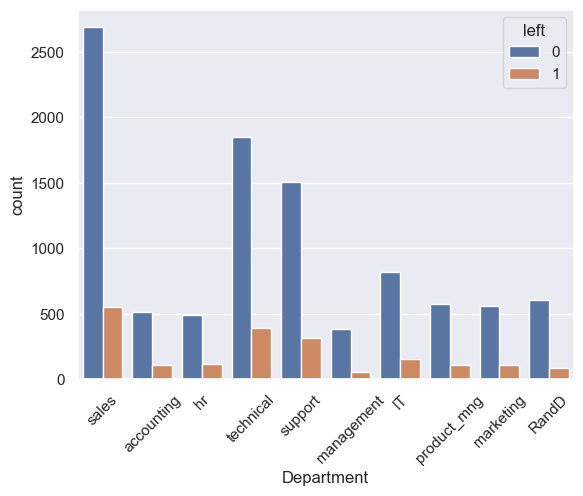

In [ ]:
sns.countplot(data=df, x="Department", hue="left")
plt.xticks(rotation=45);

In [ ]:
df.groupby("Department")["left"].value_counts(normalize=True)

Department   left
IT           0       0.838115
             1       0.161885
RandD        0       0.877522
             1       0.122478
accounting   0       0.824477
             1       0.175523
hr           0       0.811980
             1       0.188020
management   0       0.880734
             1       0.119266
marketing    0       0.833581
             1       0.166419
product_mng  0       0.839650
             1       0.160350
sales        0       0.830195
             1       0.169805
support      0       0.828666
             1       0.171334
technical    0       0.826203
             1       0.173797
Name: proportion, dtype: float64

There are 10 departments

Most employees are in Sales, Technical and Support respectively

Exit ratio in each deapartment is around 16% to 17% except: management 11% and RandD 12%

Bins:

Management and RandD --> Safe Departments

Rest --> Kinda Risky

In [ ]:
df["salary"].describe()

count     11991
unique        3
top         low
freq       5740
Name: salary, dtype: object

In [ ]:
df["salary"].unique()

array(['low', 'medium', 'high'], dtype=object)

In [ ]:
df["salary"].value_counts(normalize=True)

salary
low       0.478692
medium    0.438746
high      0.082562
Name: proportion, dtype: float64

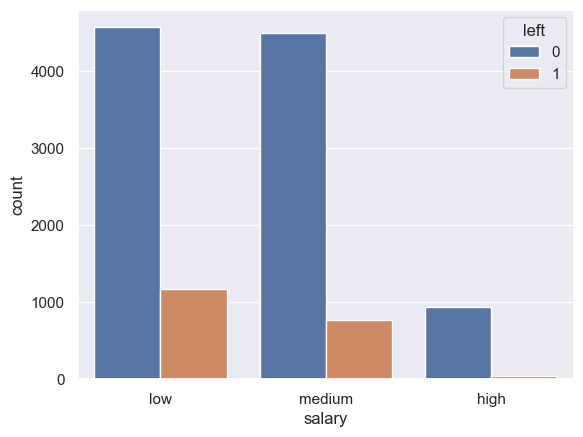

In [ ]:
sns.countplot(data=df, x="salary", hue="left");

In [ ]:
df.groupby("salary")["left"].value_counts(normalize=True)

salary  left
high    0       0.951515
        1       0.048485
low     0       0.795470
        1       0.204530
medium  0       0.853830
        1       0.146170
Name: proportion, dtype: float64

Most people have low and medium salaries

Low and medium salary empoyees have exit ratio of 20% and 14% respectively

---


# Correlation Analysis

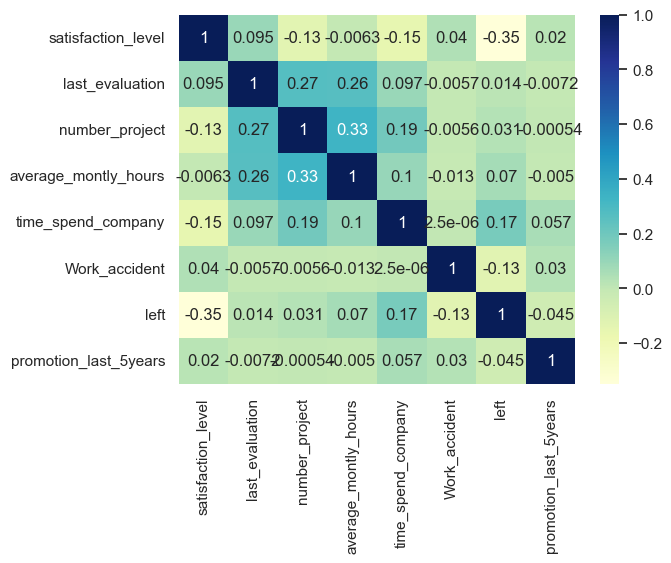

In [ ]:
corr = df.corr(numeric_only=True)

sns.heatmap(corr, annot=True, cmap="YlGnBu");

No two features have a high correlation

Some features are somewhat correlated:

* satisfaction level (-0.35) left 

* number of projects (+0.33) average monthly hours

* average monthly hours (+0.26) last evaluation

* no of projects (+0.27) last evaluation


---

# Summary

**Dataset Profile:** 14,999 employees | 10 features | Data quality is excellent (zero null values, clean data types).

---

The data reveals that employees aren't leaving for a single blanket reason. Instead, they fall into three highly specific churn buckets driven by workload and satisfaction:

* **The Overworked High-Performers:** Employees working extreme hours (>275 hrs/month), racking up high evaluation scores (0.8+), and juggling 7 projects **all leave the company (100% turnover).**
* **The Underutilized / Disengaged:** Employees working very low hours (125–155 hrs/month), hitting a satisfaction spike right at 0.4, and assigned to only 2 projects are also heavily exiting. 
* **The "Average" Slump:** There is a distinct cluster of average performers (evaluation scores around 0.50) and moderate satisfaction (0.45–0.60) who choose to walk away.

The data points to a rigid organizational culture with a severe lack of upward mobility:
* **The Promotion Drought:** Getting a promotion is incredibly rare (less than a 1% chance). Statistically, an employee is **more likely to get into a workplace accident (10%) than get a promotion (<1%).**
* **The Loyalty Anchor:** Promotions work incredibly well for retention; only 3% of the few who were promoted ended up leaving. 
* **The 3-5 Year Itch:** Employees generally stick around for 3 to 4 years, and most exits occur in the 3-5 year window. However, if they survive past 7 years, they become entirely loyal—**zero employees with 7+ years of tenure left.**

* **The Core Workforce:** The vast majority of the workforce sits within Sales, Technical, and Support roles.
* **Departmental Consistency:** Most departments suffer from an identical exit rate (~16% to 17%). The only exceptions showing noticeably better retention are **Management (11%)** and **R&D (12%)**.
* **Salary is a Major Lever:** Low-salary employees have a massive **20% exit rate**, which drops to 14% for medium salaries, and drops significantly lower for high earners.

While there is no severe multicollinearity (meaning we don't need to drop features due to redundancy), several logical relationships emerge:
* **The Burnout Loop:** More projects strongly correlate with higher monthly hours ($+0.33$) and higher evaluation scores ($+0.27$). 
* **Satisfaction Drives Churn:** Satisfaction level holds the strongest negative correlation with exits ($-0.35$). As satisfaction drops, churn reliably spikes.
* **Irrelevant Features:** Workplace accidents have no statistical impact on whether an employee decides to leave.

---

## Recommended Next Steps for Modeling

1.  **Feature Engineering:** * Create a binary feature for `Is_Overworked` (Hours > 275 AND Projects = 7).
    * Bin the `Department` column into two risk tiers: *Low Risk* (Management/R&D) and *Standard Risk* (All others).
2.  **Model Selection:** Because the relationships between hours, projects, and exiting are highly non-linear (e.g., both very low hours and very high hours cause exits), **Tree-based models** (Random Forest, XGBoost) should be prioritized over standard Logistic Regression.